In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

In [28]:
def ler_arquivo_hex(arquivo):
    valores = []
    
    with open(arquivo, 'r') as arquivo:
        for linha in arquivo:
            linha = linha.strip() # Remove espaços e quebras de linha
            if not linha:
                continue
            valor_inteiro = int(linha, 16) #le em hexa e converte pra int
            #se tiver numeros negativos
            if valor_inteiro >= 32768:
                valor_inteiro -= 65536

            valores.append(valor_inteiro)

    vetor_x = np.array(valores) / 32767.0 #converte p array do numpy e volta pra -1 a 1

    return vetor_x

In [29]:
fs = 4000
t = np.arange(0, 1.0, 1.0 / fs)  # Vetor de tempo de 1 segundo
entrada = ler_arquivo_hex('ruido_branco.hex')


In [30]:
ordem = 2
fc_hertz = 1000

# Usando 'sos' (Second-Order Sections) para maior estabilidade numérica
sos = signal.butter(N=ordem, Wn=frequencia_corte, btype='lowpass', analog=False, fs=fs, output='sos')

# --- 3. Aplicação do Filtro ---
# sosfiltfilt aplica o filtro para frente e para trás, eliminando o atraso de fase
sinal_filtrado = signal.sosfiltfilt(sos, entrada)

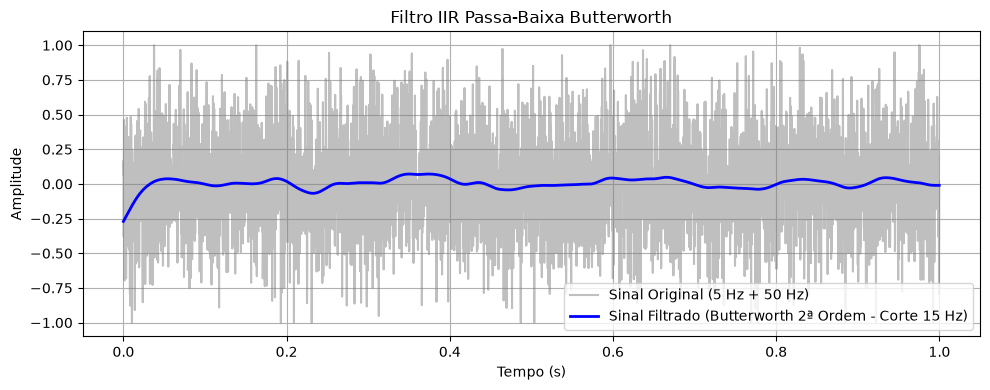

In [31]:
plt.figure(figsize=(10, 4))
plt.plot(t, entrada, label='Sinal Original (5 Hz + 50 Hz)', alpha=0.5, color='gray')
plt.plot(t, sinal_filtrado, label='Sinal Filtrado (Butterworth 2ª Ordem - Corte 15 Hz)', color='blue', linewidth=2)
plt.title('Filtro IIR Passa-Baixa Butterworth')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
